In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats import f_oneway

import re

In [ ]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    KFold,
    RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.neighbors import KNeighborsRegressor

import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

In [ ]:
df_raw = pd.read_csv("/content/Raw-Final-Rumah.csv")

df = df_raw.copy(deep=True)

In [ ]:
df.head()

,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
0,"2,5 Miliar",4,3,10,LT : 438 m²,LB : 110 m²,Tapos,129
1,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129
2,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Cipayung,129
3,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Rangkapanjaya,129
4,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129


In [ ]:
df.tail()

,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
40195,756 Juta Total,LT:168 m²,NaN,NaN,NaN,NaN,Cilodong,910
40196,"3,9 Miliar",4,2,2,LT : 375 m²,LB : 221 m²,Cinere,910
40197,7 Miliar,5,4,1,LT : 500 m²,LB : 568 m²,Cinere,910
40198,"8,5 Miliar",5,5,2,LT : 770 m²,LB : 345 m²,Cinere,910
40199,550 Juta,LB:25 m²,NaN,NaN,NaN,NaN,Margonda,910


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40200 entries, 0 to 40199
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Harga          40200 non-null  object
 1   Kamar Tidur    40191 non-null  object
 2   Kamar Mandi    35797 non-null  object
 3   Garasi         35011 non-null  object
 4   Luas Tanah     32501 non-null  object
 5   Luas Bangunan  24598 non-null  object
 6   Kecamatan      40200 non-null  object
 7   Page           40200 non-null  int64 
dtypes: int64(1), object(7)
memory usage: 2.5+ MB


In [ ]:
df.shape

(40200, 8)

In [ ]:
df.isnull().sum()

,0
Harga,0
Kamar Tidur,9
Kamar Mandi,4403
Garasi,5189
Luas Tanah,7699
Luas Bangunan,15602
Kecamatan,0
Page,0


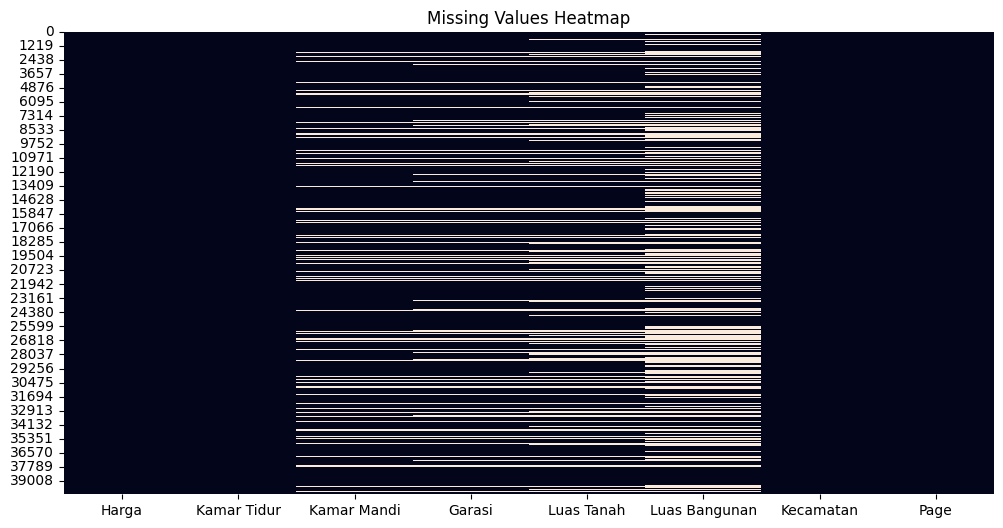

In [ ]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values Heatmap")
plt.show()

In [ ]:
df.duplicated().sum()

np.int64(1525)

In [ ]:
for col in df.columns:
  print(f"Unique values in column '{col} : ")
  print(df[col].unique())
  print("-"*30)

Unique values in column 'Harga : 
['2,5 Miliar' '385 Juta' '950 Juta' ... '711 Juta' '613 Juta'
 '20,7 Triliun Total']
------------------------------
Unique values in column 'Kamar Tidur : 
['4' '3' '2' ... 'LT:869 m²' 'LT:20459 m²' 'LT:765 m²']
------------------------------
Unique values in column 'Kamar Mandi : 
['3' '2' '1' '4' nan 'LB:1200 m²' 'LT:1050 m²' 'LT:100 m²' '5' '28' '20'
 'LB:5 m²' '7' 'LB:782 m²' 'LB:700 m²' 'LT:52 m²' '19' 'LT:2341 m²'
 'LT:705 m²' 'LT:420 m²' 'LB:185 m²' 'LB:23 m²' 'LT:300 m²' 'LT:45 m²'
 'LT:93 m²' 'LT:87 m²' 'LB:25 m²' 'LB:9636 m²' 'LT:135 m²' 'LT:75 m²'
 'LT:630 m²' 'LT:2000 m²' '8' 'LB:100 m²' '6' 'LT:1500 m²' 'LT:1095 m²'
 'LT:10000 m²' 'LB:20 m²' '24' 'LB:22 m²' 'LB:24 m²' 'LT:2246 m²' '23'
 'LT:4300 m²' 'LT:740 m²' 'LB:1500 m²' 'LB:380 m²' 'LT:419 m²' '15'
 'LT:154 m²' 'LT:74 m²' 'LB:300 m²' 'LT:500 m²' '50' 'LT:84 m²'
 'LT:765 m²' 'LT:376 m²' 'LB:42 m²' 'LT:92 m²' 'LT:680 m²' '13'
 'LT:120 m²' 'LB:60 m²' '10' 'LB:21 m²' '68' 'LT:54 m²' 'LB:27

In [ ]:
suspects = [
    "?", "??", "NA", "N/A", "na", "None", "null",
    "Null", "Unknown", "UNK", "-", "--", " ", "Nan",
    "XXX", "unk"
]

for val in suspects:
  print(f"{val}:")
  print((df == val).sum())

?:
Harga            0
Kamar Tidur      0
Kamar Mandi      0
Garasi           0
Luas Tanah       0
Luas Bangunan    0
Kecamatan        0
Page             0
dtype: int64
??:
Harga            0
Kamar Tidur      0
Kamar Mandi      0
Garasi           0
Luas Tanah       0
Luas Bangunan    0
Kecamatan        0
Page             0
dtype: int64
NA:
Harga            0
Kamar Tidur      0
Kamar Mandi      0
Garasi           0
Luas Tanah       0
Luas Bangunan    0
Kecamatan        0
Page             0
dtype: int64
N/A:
Harga            0
Kamar Tidur      0
Kamar Mandi      0
Garasi           0
Luas Tanah       0
Luas Bangunan    0
Kecamatan        0
Page             0
dtype: int64
na:
Harga            0
Kamar Tidur      0
Kamar Mandi      0
Garasi           0
Luas Tanah       0
Luas Bangunan    0
Kecamatan        0
Page             0
dtype: int64
None:
Harga            0
Kamar Tidur      0
Kamar Mandi      0
Garasi           0
Luas Tanah       0
Luas Bangunan    0
Kecamatan        0
Page            

In [ ]:
kolom_diperiksa = [
    "Kamar Tidur",
    "Kamar Mandi",
    "Garasi",
    "Luas Tanah",
    "Luas Bangunan"
]

for col in kolom_diperiksa:
    print(f"\n--- {col}: contoh nilai ---")
    display(
        df[col]
        .dropna()
        .astype(str)
        .sample(min(15, df[col].notna().sum()), random_state=42)
        .to_frame()
    )


--- Kamar Tidur: contoh nilai ---


,Kamar Tidur
31904,LT:1740 m²
3432,4
10282,3
28379,5
22781,3
32993,2
23384,3
25220,3
18190,3
27326,3



--- Kamar Mandi: contoh nilai ---


,Kamar Mandi
10940,3
38627,1
19763,LT:348 m²
21193,1
16799,3
27626,3
8467,2
4757,4
38740,2
7722,1



--- Garasi: contoh nilai ---


,Garasi
3128,LT:350 m²
308,1
38137,2
24221,1
37521,1
30613,1
27939,LT:232 m²
19653,1
3644,LB:36 m²
28210,1



--- Luas Tanah: contoh nilai ---


,Luas Tanah
28593,LB : 550 m²
28027,LT : 53 m²
15728,LT : 168 m²
36356,LT : 525 m²
5472,LT : 103 m²
26807,LB : 200 m²
12968,LT : 105 m²
26903,LT : 55 m²
17013,LT : 198 m²
30743,LT : 78 m²



--- Luas Bangunan: contoh nilai ---


,Luas Bangunan
1731,LB : 78 m²
1946,LB : 112 m²
12939,LB : 250 m²
39302,LB : 40 m²
2476,LB : 72 m²
19607,LB : 45 m²
31203,LB : 72 m²
24503,LB : 100 m²
17188,LB : 120 m²
8889,LB : 242 m²


In [ ]:
def parse_harga(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower().replace("\u00a0", " ")

    match = re.search(
        r"(\d[\d.,]*)\s*(miliar|milyar|juta|jt)\b",
        text
    )

    if not match:
        return np.nan

    angka_text = match.group(1)
    satuan = match.group(2)

    # Contoh: 2,5 -> 2.5; 1.500 -> 1500
    if "," in angka_text:
        angka_text = angka_text.replace(".", "").replace(",", ".")
    elif angka_text.count(".") > 1:
        angka_text = angka_text.replace(".", "")

    angka = float(angka_text)

    if satuan in ["miliar", "milyar"]:
        return angka * 1_000_000_000

    return angka * 1_000_000


def parse_angka(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip()

    # Hanya menerima isi berupa angka, bukan teks campuran.
    if re.fullmatch(r"\d+(?:[.,]\d+)?", text):
        return float(text.replace(",", "."))

    return np.nan


def parse_luas(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower()
    match = re.search(r"(\d+(?:[.,]\d+)?)\s*m²", text)

    if not match:
        return np.nan

    return float(match.group(1).replace(",", "."))

In [ ]:
df_eda = df.copy()

df_eda["Harga_Rp"] = df_eda["Harga"].apply(parse_harga)

for col in ["Kamar Tidur", "Kamar Mandi", "Garasi"]:
    df_eda[col + "_num"] = df_eda[col].apply(parse_angka)

for col in ["Luas Tanah", "Luas Bangunan"]:
    df_eda[col + "_num"] = df_eda[col].apply(parse_luas)

kolom_numerik_bersih = [
    "Harga_Rp",
    "Kamar Tidur_num",
    "Kamar Mandi_num",
    "Garasi_num",
    "Luas Tanah_num",
    "Luas Bangunan_num"
]

display(df_eda[kolom_numerik_bersih].describe().T)

,count,mean,std,min,25%,50%,75%,max
Harga_Rp,40080.0,5.083868e+09,2.957825e+10,1030000.0,760000000.0,1.500000e+09,3.300000e+09,9.990000e+11
Kamar Tidur_num,35250.0,3.668652e+00,4.719539e+00,1.0,2.0,3.000000e+00,4.000000e+00,2.840000e+02
Kamar Mandi_num,33636.0,2.749049e+00,3.678546e+00,1.0,1.0,2.000000e+00,3.000000e+00,1.800000e+02
Garasi_num,24607.0,1.590442e+00,1.396581e+00,1.0,1.0,1.000000e+00,2.000000e+00,3.000000e+01
Luas Tanah_num,32501.0,2.540685e+04,4.541821e+06,1.0,67.0,1.000000e+02,2.000000e+02,8.188011e+08
Luas Bangunan_num,24598.0,4.244153e+03,6.376080e+05,1.0,60.0,1.000000e+02,1.980000e+02,1.000000e+08


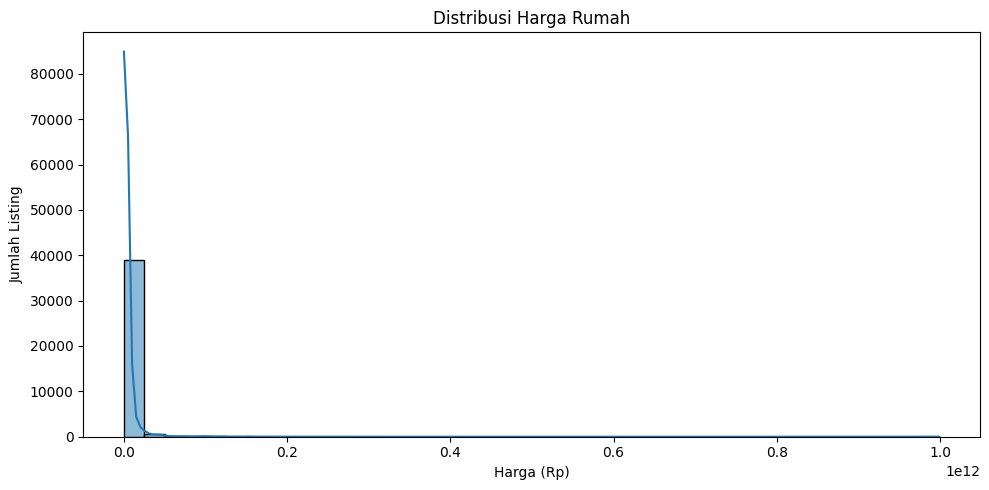

In [ ]:
# Distribusi harga
harga = df_eda["Harga_Rp"].dropna()

plt.figure(figsize=(10, 5))
sns.histplot(harga, bins=40, kde=True)
plt.title("Distribusi Harga Rumah")
plt.xlabel("Harga (Rp)")
plt.ylabel("Jumlah Listing")
plt.tight_layout()
plt.show()

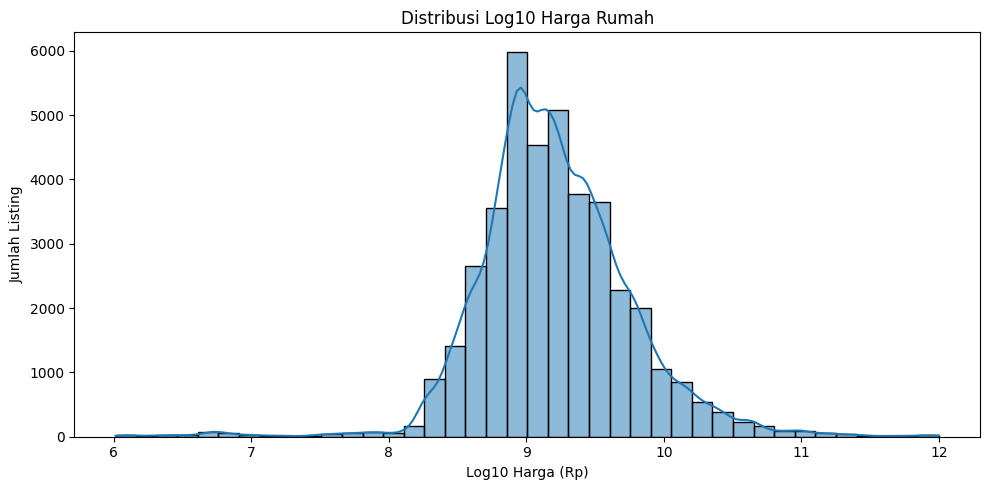

In [ ]:
harga_positif = harga[harga > 0]

plt.figure(figsize=(10, 5))
sns.histplot(np.log10(harga_positif), bins=40, kde=True)
plt.title("Distribusi Log10 Harga Rumah")
plt.xlabel("Log10 Harga (Rp)")
plt.ylabel("Jumlah Listing")
plt.tight_layout()
plt.show()

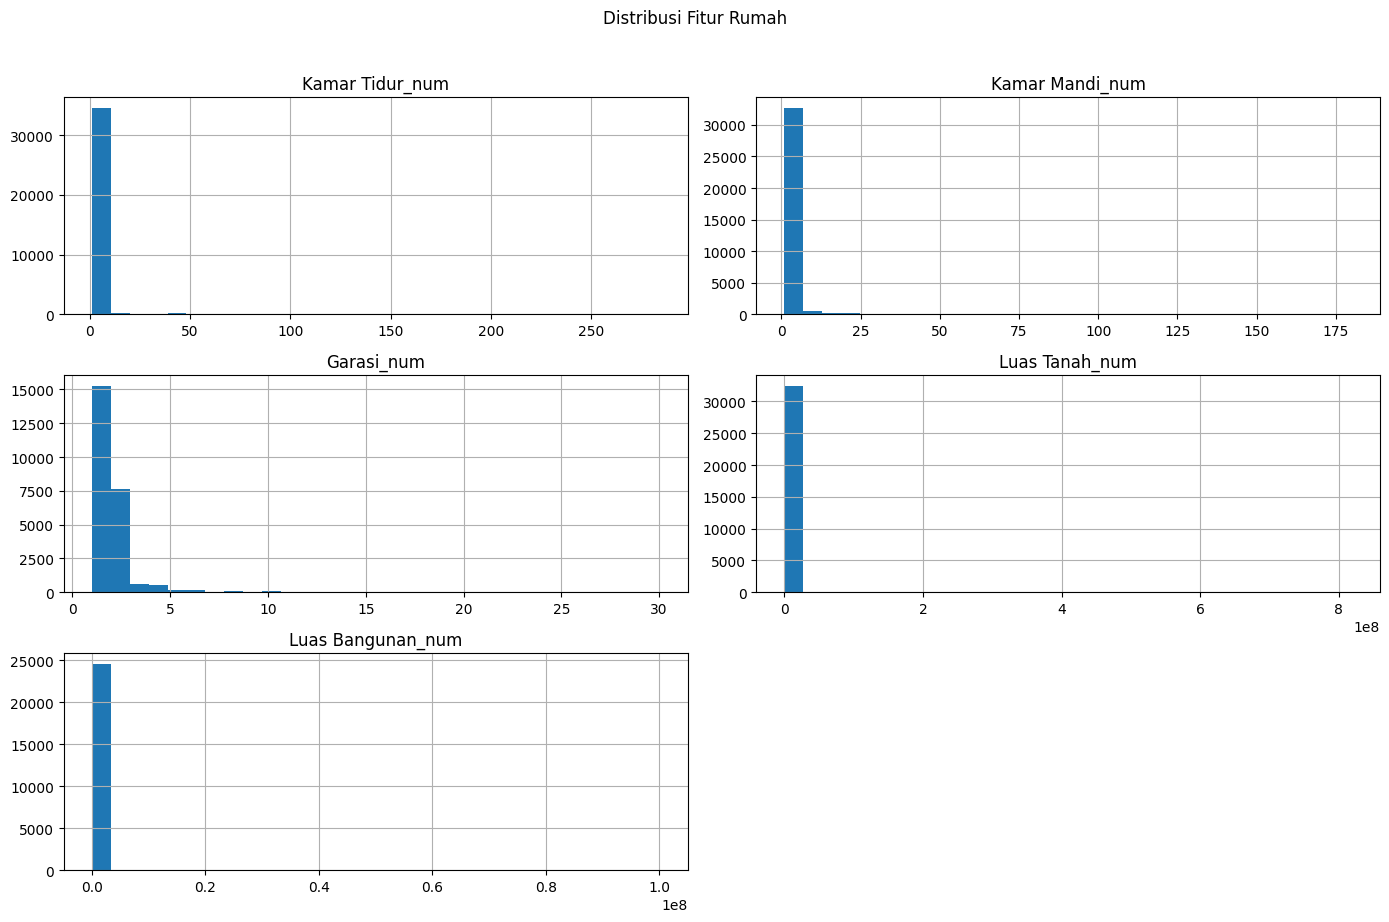

In [ ]:
fitur_plot = [
    "Kamar Tidur_num",
    "Kamar Mandi_num",
    "Garasi_num",
    "Luas Tanah_num",
    "Luas Bangunan_num"
]

df_eda[fitur_plot].hist(figsize=(14, 9), bins=30)
plt.suptitle("Distribusi Fitur Rumah", y=1.02)
plt.tight_layout()
plt.show()

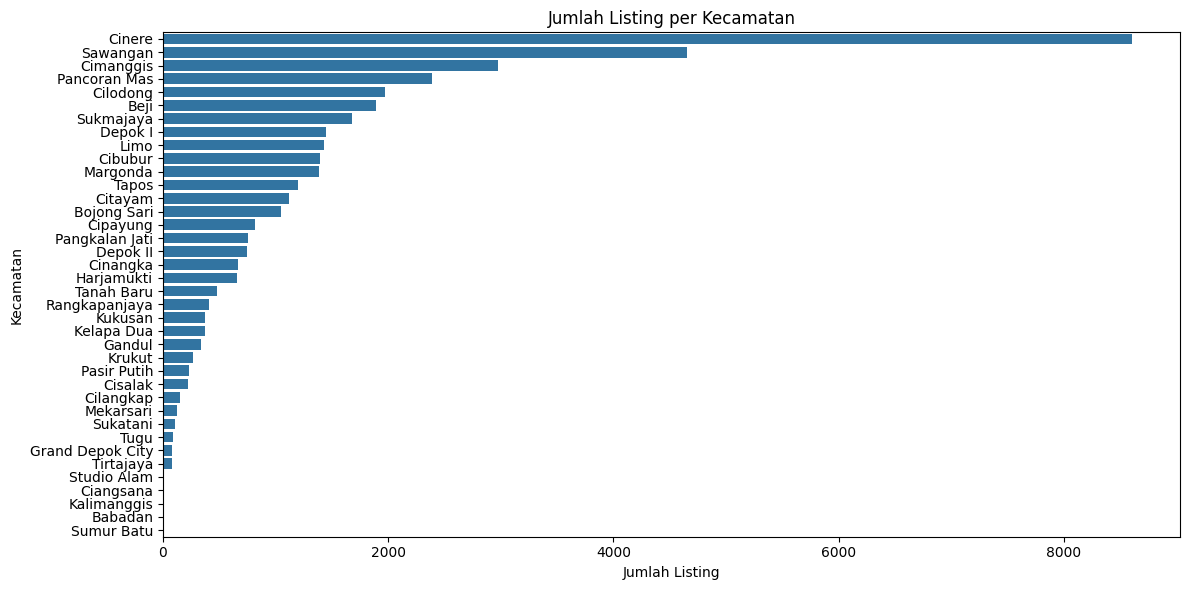

In [ ]:
plt.figure(figsize=(12, 6))
urutan = df_eda["Kecamatan"].value_counts().index

sns.countplot(
    data=df_eda,
    y="Kecamatan",
    order=urutan
)

plt.title("Jumlah Listing per Kecamatan")
plt.xlabel("Jumlah Listing")
plt.ylabel("Kecamatan")
plt.tight_layout()
plt.show()

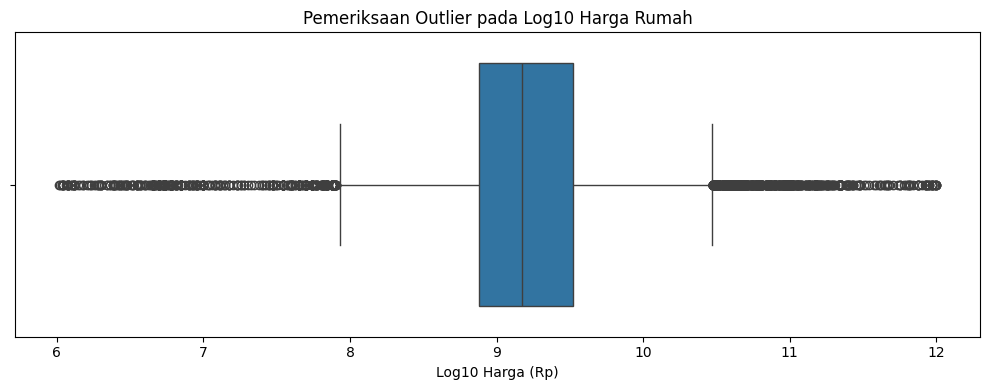

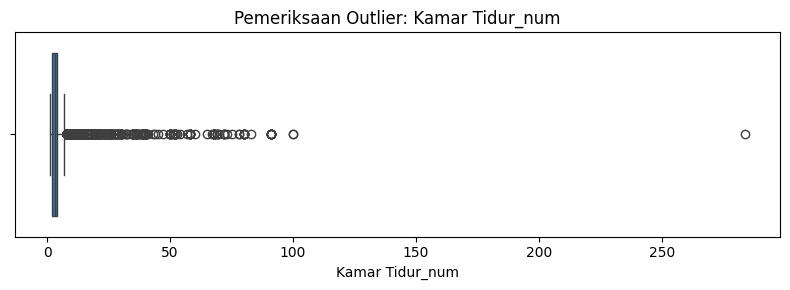

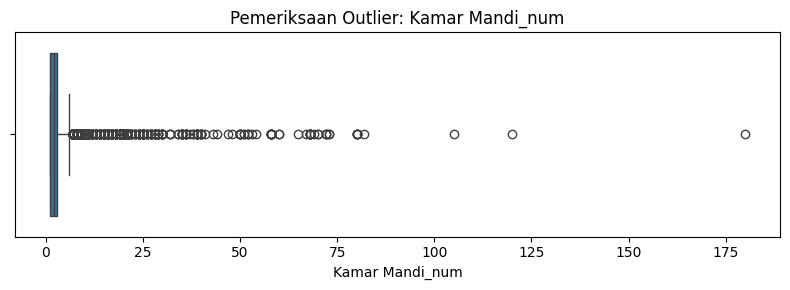

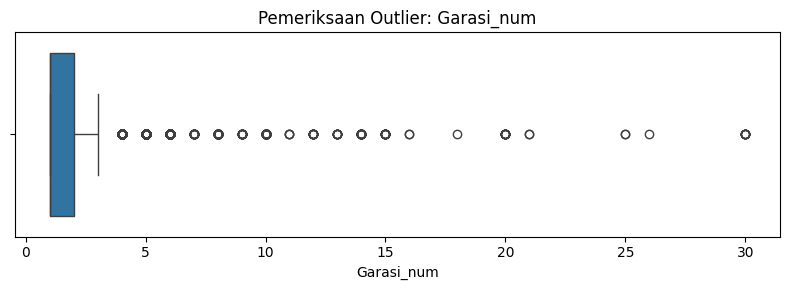

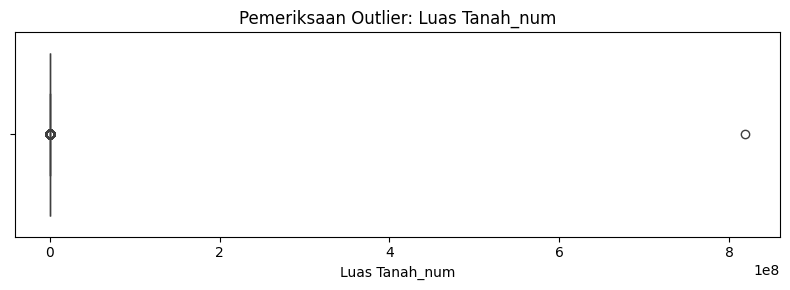

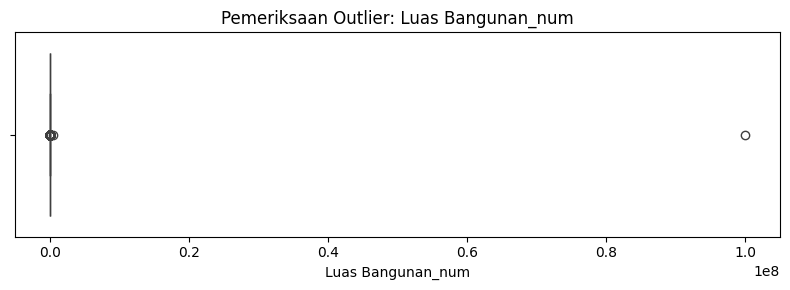

In [ ]:
# Boxplot harga; gunakan harga positif agar skala log valid
plt.figure(figsize=(10, 4))
sns.boxplot(x=np.log10(harga_positif))
plt.title("Pemeriksaan Outlier pada Log10 Harga Rumah")
plt.xlabel("Log10 Harga (Rp)")
plt.tight_layout()
plt.show()

# Boxplot per fitur dengan satuan terpisah
for col in fitur_plot:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df_eda[col])
    plt.title(f"Pemeriksaan Outlier: {col}")
    plt.tight_layout()
    plt.show()

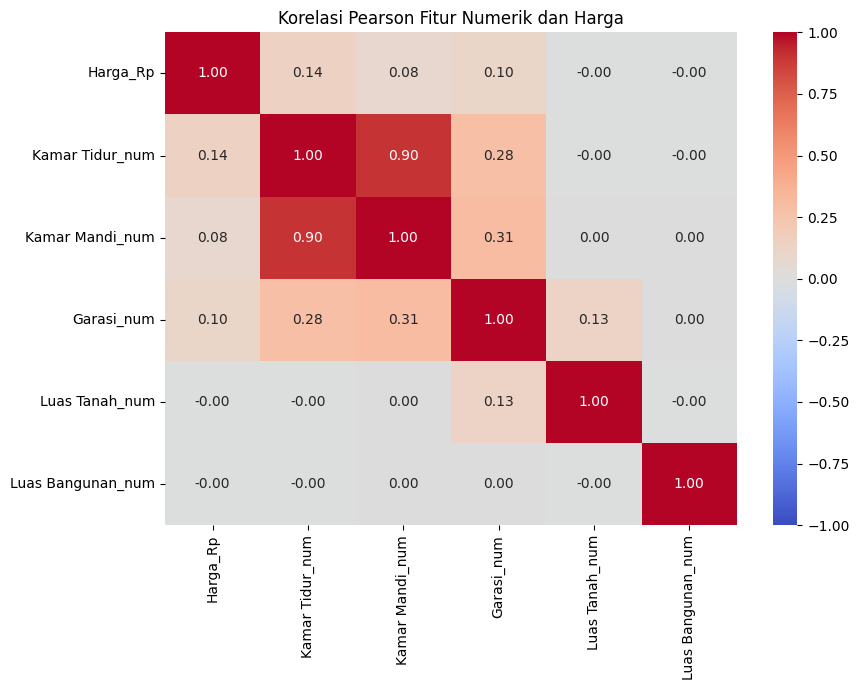

In [ ]:
kolom_korelasi = [
    "Harga_Rp",
    "Kamar Tidur_num",
    "Kamar Mandi_num",
    "Garasi_num",
    "Luas Tanah_num",
    "Luas Bangunan_num"
]

pearson_matrix = df_eda[kolom_korelasi].corr(method="pearson")

plt.figure(figsize=(9, 7))
sns.heatmap(
    pearson_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Korelasi Pearson Fitur Numerik dan Harga")
plt.tight_layout()
plt.show()

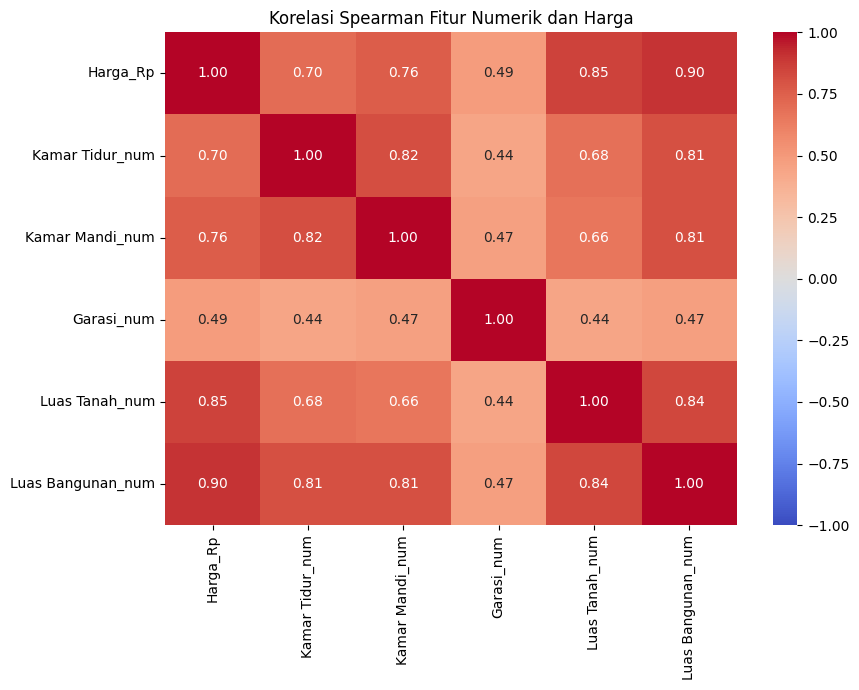

In [ ]:
spearman_matrix = df_eda[kolom_korelasi].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(
    spearman_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Korelasi Spearman Fitur Numerik dan Harga")
plt.tight_layout()
plt.show()

In [ ]:
ringkasan_kecamatan = (
    df_eda.dropna(subset=["Harga_Rp"])
    .groupby("Kecamatan")["Harga_Rp"]
    .agg(
        Jumlah="count",
        Median="median",
        Rata_rata="mean",
        Minimum="min",
        Maksimum="max"
    )
    .sort_values("Median", ascending=False)
)

display(ringkasan_kecamatan)

,Jumlah,Median,Rata_rata,Minimum,Maksimum
Kecamatan,,,,,
Sumur Batu,1,1.200000e+11,1.200000e+11,1.200000e+11,1.200000e+11
Pangkalan Jati,752,4.400000e+09,7.738045e+09,4.850000e+06,7.000000e+11
Cinere,8585,3.000000e+09,5.063647e+09,1.100000e+06,9.950000e+11
Cibubur,1392,2.125000e+09,5.934291e+09,1.270000e+06,8.500000e+11
Gandul,337,2.100000e+09,4.585181e+09,1.950000e+06,1.545000e+11
Harjamukti,657,1.800000e+09,4.330746e+09,3.600000e+06,3.750000e+11
Tugu,91,1.600000e+09,6.146538e+09,6.000000e+08,7.000000e+10
Mekarsari,128,1.570000e+09,4.824844e+09,3.750000e+08,6.280000e+10
Cisalak,219,1.550000e+09,5.655316e+09,8.500000e+06,9.500000e+10


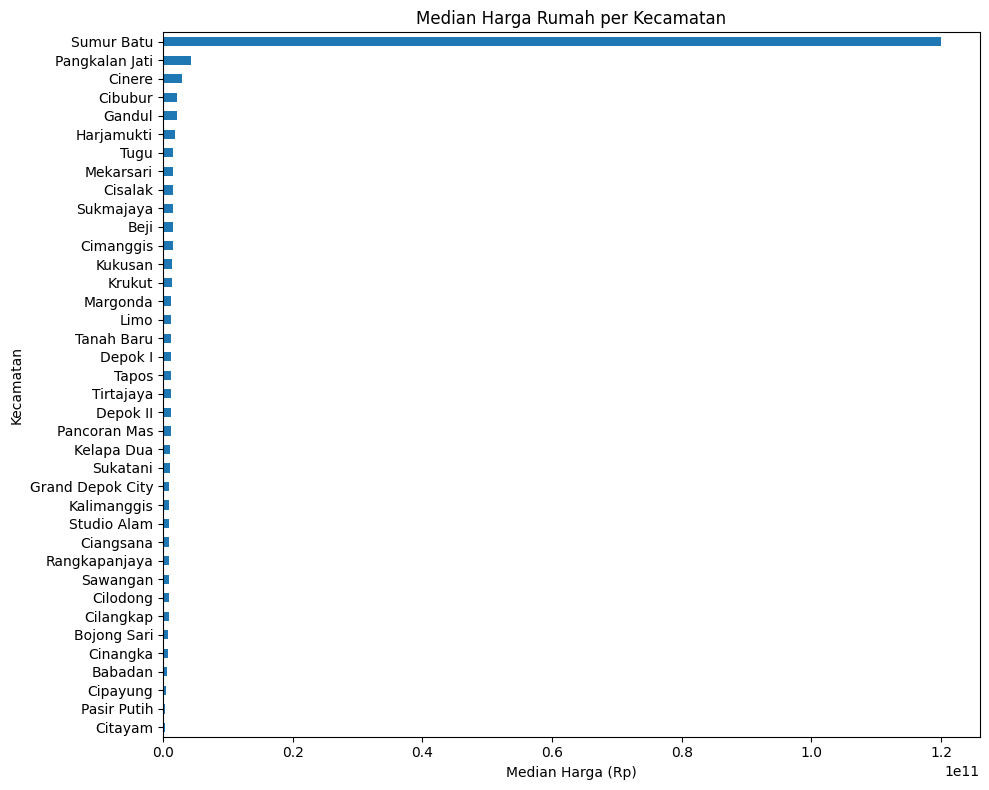

In [ ]:
median_kecamatan = (
    df_eda.dropna(subset=["Harga_Rp"])
    .groupby("Kecamatan")["Harga_Rp"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 8))
median_kecamatan.plot(kind="barh")
plt.title("Median Harga Rumah per Kecamatan")
plt.xlabel("Median Harga (Rp)")
plt.ylabel("Kecamatan")
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import kruskal

kelompok_harga = [
    grup["Harga_Rp"].dropna().to_numpy()
    for _, grup in df_eda.groupby("Kecamatan")
]

kelompok_harga = [g for g in kelompok_harga if len(g) > 0]

if len(kelompok_harga) >= 2:
    statistik, p_value = kruskal(*kelompok_harga)
    print("Statistik Kruskal-Wallis:", statistik)
    print("P-value:", p_value)

Statistik Kruskal-Wallis: 9310.092213447115
P-value: 0.0


Tahap 2

In [ ]:
# Parsing minimum untuk baseline
def parse_angka(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip()

    # Hanya menerima angka sederhana, bukan teks berlabel LT/LB
    if re.fullmatch(r"\d+(?:[.,]\d+)?", text):
        return float(text.replace(",", "."))

    return np.nan


df_base = df_raw.copy()

df_base["Harga_Rp"] = df_base["Harga"].apply(parse_harga)

for col in [
    "Kamar Tidur",
    "Kamar Mandi",
    "Garasi"
]:
    df_base[col] = df_base[col].apply(parse_angka)


def parse_area_baseline(value):
    if pd.isna(value):
        return np.nan

    match = re.search(
        r"(\d+(?:[.,]\d+)?)\s*m²",
        str(value).lower()
    )

    if not match:
        return np.nan

    return float(match.group(1).replace(",", "."))


for col in ["Luas Tanah", "Luas Bangunan"]:
    df_base[col] = df_base[col].apply(parse_area_baseline)

df_base = df_base.dropna(subset=["Harga_Rp"]).copy()

print("Ukuran data baseline:", df_base.shape)
display(df_base.head())

Ukuran data baseline: (40080, 9)


,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page,Harga_Rp
0,"2,5 Miliar",4.0,3.0,10.0,438.0,110.0,Tapos,129,2.500000e+09
1,385 Juta,3.0,2.0,1.0,50.0,60.0,Pancoran Mas,129,3.850000e+08
2,385 Juta,3.0,2.0,1.0,50.0,60.0,Cipayung,129,3.850000e+08
3,385 Juta,3.0,2.0,1.0,50.0,60.0,Rangkapanjaya,129,3.850000e+08
4,385 Juta,3.0,2.0,1.0,50.0,60.0,Pancoran Mas,129,3.850000e+08


In [ ]:
fitur = [
    "Kamar Tidur",
    "Kamar Mandi",
    "Garasi",
    "Luas Tanah",
    "Luas Bangunan",
    "Kecamatan"
]

X = df_base[fitur].copy()
y = df_base["Harga_Rp"].copy()

# Indeks training dan test disimpan agar bisa dipakai
# kembali pada tahap setelah preprocessing.
train_idx, test_idx = train_test_split(
    df_base.index,
    test_size=0.20,
    random_state=42
)

X_train = X.loc[train_idx]
X_test = X.loc[test_idx]

y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

print("Data training:", X_train.shape)
print("Data testing :", X_test.shape)

Data training: (32064, 6)
Data testing : (8016, 6)


In [ ]:
kolom_numerik = [
    "Kamar Tidur",
    "Kamar Mandi",
    "Garasi",
    "Luas Tanah",
    "Luas Bangunan"
]

kolom_kategori = ["Kecamatan"]

prep_baseline = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            kolom_numerik
        ),
        (
            "cat",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="constant",
                        fill_value="Unknown"
                    )
                ),
                (
                    "onehot",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            kolom_kategori
        )
    ]
)

In [ ]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=5
    )
}

In [ ]:
def evaluasi(y_true, y_pred):
    # MAPE tidak terdefinisi jika harga aktual nol.
    mask = np.asarray(y_true) != 0

    mape = (
        mean_absolute_percentage_error(
            np.asarray(y_true)[mask],
            np.asarray(y_pred)[mask]
        ) * 100
        if mask.any()
        else np.nan
    )

    return {
        "MAE (Rp)": mean_absolute_error(y_true, y_pred),
        "MAPE (%)": mape,
        "R2": r2_score(y_true, y_pred)
    }

In [ ]:
hasil_baseline = []
model_baseline_fitted = {}

for nama, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", prep_baseline),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    hasil = evaluasi(y_test, pred)
    hasil["Model"] = nama

    hasil_baseline.append(hasil)
    model_baseline_fitted[nama] = pipeline

hasil_baseline = pd.DataFrame(hasil_baseline)

display(
    hasil_baseline[
        ["Model", "MAE (Rp)", "MAPE (%)", "R2"]
    ].sort_values("MAE (Rp)")
)

,Model,MAE (Rp),MAPE (%),R2
2,Random Forest,4.089069e+09,1932.926323,-0.123205
4,KNN,4.148750e+09,1516.091897,-0.162256
1,Decision Tree,4.237110e+09,1908.524784,-0.412571
3,Gradient Boosting,4.399196e+09,1716.117301,0.011676
0,Linear Regression,5.624022e+09,1380.098037,-0.000406


3

In [ ]:
def parse_area_label(value):
    """
    Mengembalikan (label, nilai).
    Label berupa LT atau LB.
    """
    if pd.isna(value):
        return None, np.nan

    text = str(value).strip().lower()

    match = re.search(
        r"\b(lt|lb)\b\s*:?\s*(\d+(?:[.,]\d+)?)\s*m(?:²|2)\b",
        text
    )

    if not match:
        return None, np.nan

    label = match.group(1).upper()
    nilai = float(match.group(2).replace(",", "."))

    return label, nilai

In [ ]:
for value in [
    "LT : 438 m²",
    "LB : 110 m²",
    "LB:41 m²",
    "LT:1000 m²"
]:
    print(value, "=>", parse_area_label(value))

LT : 438 m² => ('LT', 438.0)
LB : 110 m² => ('LB', 110.0)
LB:41 m² => ('LB', 41.0)
LT:1000 m² => ('LT', 1000.0)


In [ ]:
def repair_area_row(row):
    sumber = [
        "Kamar Tidur",
        "Kamar Mandi",
        "Garasi",
        "Luas Tanah",
        "Luas Bangunan"
    ]

    kandidat_lt = []
    kandidat_lb = []

    for col in sumber:
        label, nilai = parse_area_label(row[col])

        if label == "LT":
            kandidat_lt.append(nilai)
        elif label == "LB":
            kandidat_lb.append(nilai)

    # Mengambil nilai dari kolom utama jika nilainya memang
    # berlabel sesuai dan tidak bertentangan dengan sumber lain.
    def pilih_nilai(kandidat):
        nilai_unik = sorted(set(kandidat))

        if len(nilai_unik) == 1:
            return nilai_unik[0], False

        if len(nilai_unik) == 0:
            return np.nan, False

        # Jika ada nilai yang bertentangan, jangan menebak.
        return np.nan, True

    lt, konflik_lt = pilih_nilai(kandidat_lt)
    lb, konflik_lb = pilih_nilai(kandidat_lb)

    return pd.Series({
        "LT_recovered": lt,
        "LB_recovered": lb,
        "Konflik_LT": konflik_lt,
        "Konflik_LB": konflik_lb
    })


hasil_repair = df_raw.apply(repair_area_row, axis=1)

df_clean = df_raw.copy()

df_clean["LT_recovered"] = hasil_repair["LT_recovered"]
df_clean["LB_recovered"] = hasil_repair["LB_recovered"]
df_clean["Konflik_LT"] = hasil_repair["Konflik_LT"]
df_clean["Konflik_LB"] = hasil_repair["Konflik_LB"]

display(
    df_clean[
        [
            "Kamar Tidur",
            "Kamar Mandi",
            "Garasi",
            "Luas Tanah",
            "Luas Bangunan",
            "LT_recovered",
            "LB_recovered",
            "Konflik_LT",
            "Konflik_LB"
        ]
    ].head(15)
)

,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,LT_recovered,LB_recovered,Konflik_LT,Konflik_LB
0,4,3,10,LT : 438 m²,LB : 110 m²,438.0,110.0,False,False
1,3,2,1,LT : 50 m²,LB : 60 m²,50.0,60.0,False,False
2,3,2,1,LT : 50 m²,LB : 60 m²,50.0,60.0,False,False
3,3,2,1,LT : 50 m²,LB : 60 m²,50.0,60.0,False,False
4,3,2,1,LT : 50 m²,LB : 60 m²,50.0,60.0,False,False
5,3,2,1,LT : 50 m²,LB : 60 m²,50.0,60.0,False,False
6,2,1,1,LT : 87 m²,LB : 50 m²,87.0,50.0,False,False
7,2,1,LB:41 m²,NaN,NaN,NaN,41.0,False,False
8,3,2,LT:409 m²,LB : 300 m²,NaN,409.0,300.0,False,False
9,4,3,LT:280 m²,LB : 240 m²,NaN,280.0,240.0,False,False


In [ ]:
print(
    "Luas tanah berhasil dipulihkan:",
    df_clean["LT_recovered"].notna().sum()
)

print(
    "Luas bangunan berhasil dipulihkan:",
    df_clean["LB_recovered"].notna().sum()
)

print(
    "Baris dengan konflik LT:",
    df_clean["Konflik_LT"].sum()
)

print(
    "Baris dengan konflik LB:",
    df_clean["Konflik_LB"].sum()
)

Luas tanah berhasil dipulihkan: 38736
Luas bangunan berhasil dipulihkan: 35869
Baris dengan konflik LT: 0
Baris dengan konflik LB: 0


In [ ]:
for col in ["Kamar Tidur", "Kamar Mandi", "Garasi"]:
    df_clean[col + "_num"] = df_clean[col].apply(parse_angka)

df_clean["Harga_Rp"] = df_clean["Harga"].apply(parse_harga)

df_clean["Luas Tanah_num"] = df_clean["LT_recovered"]
df_clean["Luas Bangunan_num"] = df_clean["LB_recovered"]

In [ ]:
kolom_num = [
    "Harga_Rp",
    "Kamar Tidur_num",
    "Kamar Mandi_num",
    "Garasi_num",
    "Luas Tanah_num",
    "Luas Bangunan_num"
]

display(df_clean[kolom_num].describe().T)

In [ ]:
audit = pd.DataFrame({
    "Missing Sebelum": df_raw.isna().sum(),
    "Missing Sesudah Parsing": df_clean[
        [
            "Harga_Rp",
            "Kamar Tidur_num",
            "Kamar Mandi_num",
            "Garasi_num",
            "Luas Tanah_num",
            "Luas Bangunan_num"
        ]
    ].isna().sum().reindex([
        "Harga_Rp",
        "Kamar Tidur_num",
        "Kamar Mandi_num",
        "Garasi_num",
        "Luas Tanah_num",
        "Luas Bangunan_num"
    ])
})

display(audit)

,Missing Sebelum,Missing Sesudah Parsing
Garasi,5189.0,NaN
Garasi_num,NaN,15593.0
Harga,0.0,NaN
Harga_Rp,NaN,120.0
Kamar Mandi,4403.0,NaN
Kamar Mandi_num,NaN,6564.0
Kamar Tidur,9.0,NaN
Kamar Tidur_num,NaN,4950.0
Kecamatan,0.0,NaN
Luas Bangunan,15602.0,NaN


In [ ]:
audit = pd.DataFrame({
    "Missing Sebelum": df_raw.isna().sum(),
    "Missing Sesudah Parsing": df_clean[
        [
            "Harga_Rp",
            "Kamar Tidur_num",
            "Kamar Mandi_num",
            "Garasi_num",
            "Luas Tanah_num",
            "Luas Bangunan_num"
        ]
    ].isna().sum().reindex([
        "Harga_Rp",
        "Kamar Tidur_num",
        "Kamar Mandi_num",
        "Garasi_num",
        "Luas Tanah_num",
        "Luas Bangunan_num"
    ])
})

display(audit)

,Missing Sebelum,Missing Sesudah Parsing
Garasi,5189.0,NaN
Garasi_num,NaN,15593.0
Harga,0.0,NaN
Harga_Rp,NaN,120.0
Kamar Mandi,4403.0,NaN
Kamar Mandi_num,NaN,6564.0
Kamar Tidur,9.0,NaN
Kamar Tidur_num,NaN,4950.0
Kecamatan,0.0,NaN
Luas Bangunan,15602.0,NaN


In [ ]:
print("Duplikat persis:", df_raw.duplicated().sum())

Duplikat persis: 1525


In [ ]:
df_unique = df_raw.drop_duplicates().copy()

print("Baris sebelum:", len(df_raw))
print("Baris sesudah:", len(df_unique))
print("Baris dihapus:", len(df_raw) - len(df_unique))

Baris sebelum: 40200
Baris sesudah: 38675
Baris dihapus: 1525


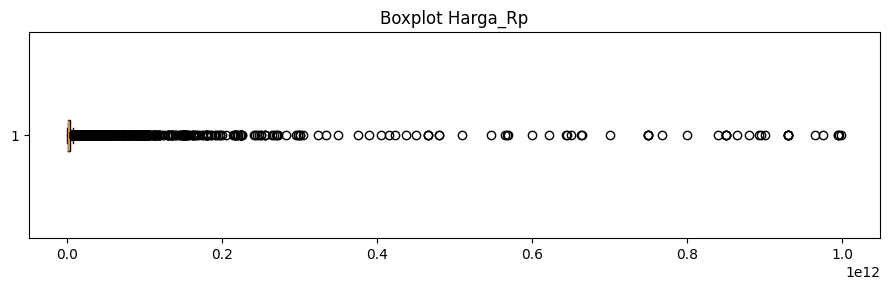

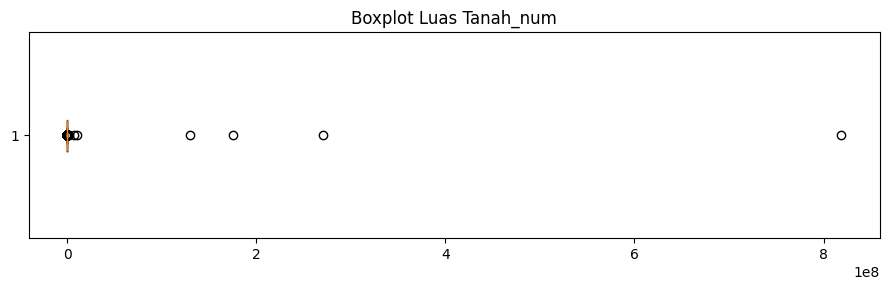

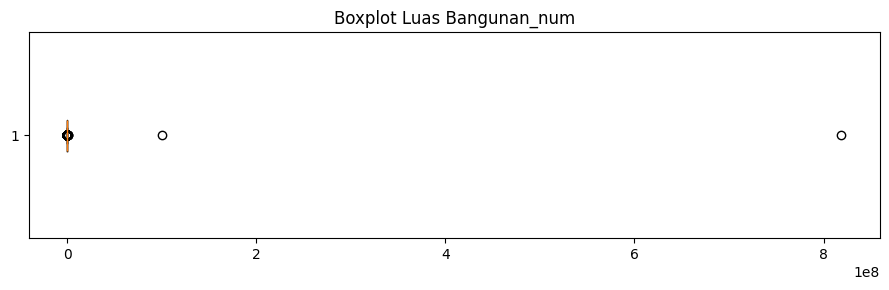

In [ ]:
for col in [
    "Harga_Rp",
    "Luas Tanah_num",
    "Luas Bangunan_num"
]:
    values = df_clean[col].dropna()

    plt.figure(figsize=(9, 3))
    plt.boxplot(values, vert=False)
    plt.title(f"Boxplot {col}")
    plt.tight_layout()
    plt.show()

In [ ]:
def iqr_outlier_summary(series):
    s = series.dropna()

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (s < lower) | (s > upper)

    return {
        "Q1": q1,
        "Q3": q3,
        "Batas Bawah": lower,
        "Batas Atas": upper,
        "Jumlah Kandidat Outlier": int(mask.sum())
    }


for col in [
    "Harga_Rp",
    "Luas Tanah_num",
    "Luas Bangunan_num"
]:
    print(col, iqr_outlier_summary(df_clean[col]))

Harga_Rp {'Q1': np.float64(760000000.0), 'Q3': np.float64(3300000000.0), 'Batas Bawah': np.float64(-3050000000.0), 'Batas Atas': np.float64(7110000000.0), 'Jumlah Kandidat Outlier': 4138}
Luas Tanah_num {'Q1': np.float64(72.0), 'Q3': np.float64(285.0), 'Batas Bawah': np.float64(-247.5), 'Batas Atas': np.float64(604.5), 'Jumlah Kandidat Outlier': 4916}
Luas Bangunan_num {'Q1': np.float64(60.0), 'Q3': np.float64(200.0), 'Batas Bawah': np.float64(-150.0), 'Batas Atas': np.float64(410.0), 'Jumlah Kandidat Outlier': 3026}


4

In [ ]:
fitur_clean = [
    "Kamar Tidur_num",
    "Kamar Mandi_num",
    "Garasi_num",
    "Luas Tanah_num",
    "Luas Bangunan_num",
    "Kecamatan"
]

df_model = df_clean.dropna(subset=["Harga_Rp"]).copy()

X_clean = df_model[fitur_clean]
y_clean = df_model["Harga_Rp"]

In [ ]:
kolom_numerik_clean = [
    "Kamar Tidur_num",
    "Kamar Mandi_num",
    "Garasi_num",
    "Luas Tanah_num",
    "Luas Bangunan_num"
]

kolom_kategori_clean = ["Kecamatan"]

prep_clean = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            kolom_numerik_clean
        ),
        (
            "cat",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="constant",
                        fill_value="Unknown"
                    )
                ),
                (
                    "onehot",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            kolom_kategori_clean
        )
    ]
)

In [ ]:
models_clean = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),
    "KNN": KNeighborsRegressor(n_neighbors=5)
}

In [ ]:
hasil_clean = []
model_clean_fitted = {}

# Untuk implementasi final, gunakan train_idx dan test_idx
# yang telah disesuaikan dengan deduplikasi dan pemulihan data.
# Contoh berikut mengasumsikan indeks train/test sudah cocok.
train_clean_idx = X_clean.index.intersection(train_idx)
test_clean_idx = X_clean.index.intersection(test_idx)

X_train_clean = X_clean.loc[train_clean_idx]
X_test_clean = X_clean.loc[test_clean_idx]

y_train_clean = y_clean.loc[train_clean_idx]
y_test_clean = y_clean.loc[test_clean_idx]

for nama, model in models_clean.items():
    pipeline = Pipeline([
        ("preprocessing", prep_clean),
        ("model", model)
    ])

    pipeline.fit(X_train_clean, y_train_clean)
    pred = pipeline.predict(X_test_clean)

    hasil = evaluasi(y_test_clean, pred)
    hasil["Model"] = nama

    hasil_clean.append(hasil)
    model_clean_fitted[nama] = pipeline

hasil_clean = pd.DataFrame(hasil_clean)

display(
    hasil_clean[
        ["Model", "MAE (Rp)", "MAPE (%)", "R2"]
    ].sort_values("MAE (Rp)")
)

,Model,MAE (Rp),MAPE (%),R2
2,Random Forest,2.215498e+09,3206.786056,0.199818
1,Decision Tree,2.426272e+09,3473.266349,-0.186136
4,KNN,2.463063e+09,3438.880146,0.195536
3,Gradient Boosting,2.498787e+09,3705.330625,0.393060
0,Linear Regression,5.624325e+09,1380.468896,-0.000362


In [ ]:
perbandingan = hasil_baseline.merge(
    hasil_clean,
    on="Model",
    suffixes=("_Baseline", "_Clean")
)

display(perbandingan)

,MAE (Rp)_Baseline,MAPE (%)_Baseline,R2_Baseline,Model,MAE (Rp)_Clean,MAPE (%)_Clean,R2_Clean
0,5.624022e+09,1380.098037,-0.000406,Linear Regression,5.624325e+09,1380.468896,-0.000362
1,4.237110e+09,1908.524784,-0.412571,Decision Tree,2.426272e+09,3473.266349,-0.186136
2,4.089069e+09,1932.926323,-0.123205,Random Forest,2.215498e+09,3206.786056,0.199818
3,4.399196e+09,1716.117301,0.011676,Gradient Boosting,2.498787e+09,3705.330625,0.393060
4,4.148750e+09,1516.091897,-0.162256,KNN,2.463063e+09,3438.880146,0.195536


5

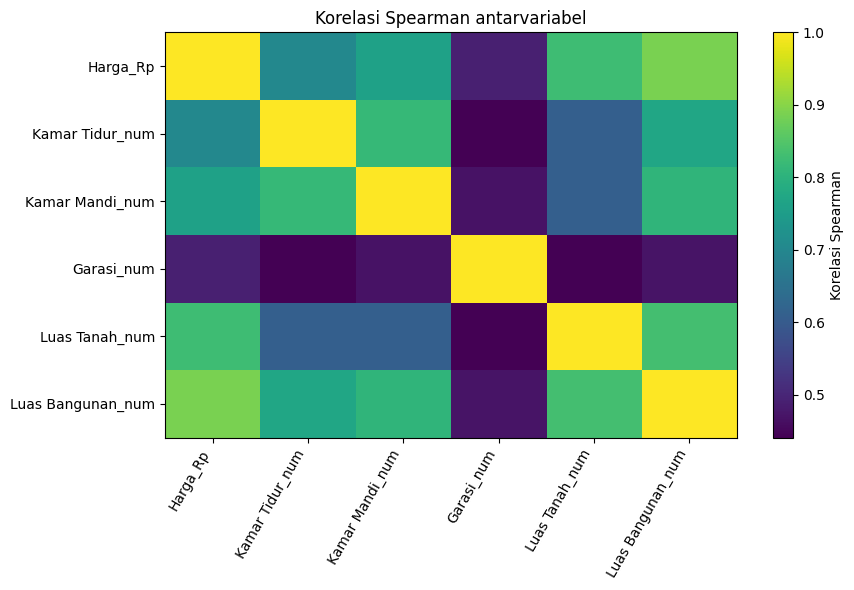

,Harga_Rp,Kamar Tidur_num,Kamar Mandi_num,Garasi_num,Luas Tanah_num,Luas Bangunan_num
Harga_Rp,1.000000,0.700853,0.761085,0.489532,0.826060,0.888004
Kamar Tidur_num,0.700853,1.000000,0.814975,0.440806,0.609016,0.772317
Kamar Mandi_num,0.761085,0.814975,1.000000,0.467208,0.609388,0.806063
Garasi_num,0.489532,0.440806,0.467208,1.000000,0.442901,0.469885
Luas Tanah_num,0.826060,0.609016,0.609388,0.442901,1.000000,0.833117
Luas Bangunan_num,0.888004,0.772317,0.806063,0.469885,0.833117,1.000000


In [ ]:
fitur_korelasi = [
    "Harga_Rp",
    "Kamar Tidur_num",
    "Kamar Mandi_num",
    "Garasi_num",
    "Luas Tanah_num",
    "Luas Bangunan_num"
]

corr = df_model[fitur_korelasi].corr(method="spearman")

plt.figure(figsize=(9, 6))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Korelasi Spearman")
plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=60,
    ha="right"
)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Korelasi Spearman antarvariabel")
plt.tight_layout()
plt.show()

display(corr)

,Fitur,Importance,Std
3,Luas Tanah_num,5.597963e+09,1.184970e+08
4,Luas Bangunan_num,2.236189e+09,1.456847e+08
5,Kecamatan,1.208470e+09,1.141572e+08
0,Kamar Tidur_num,2.736670e+08,1.607947e+07
1,Kamar Mandi_num,2.551108e+08,2.456800e+07
2,Garasi_num,4.928276e+07,5.177161e+07


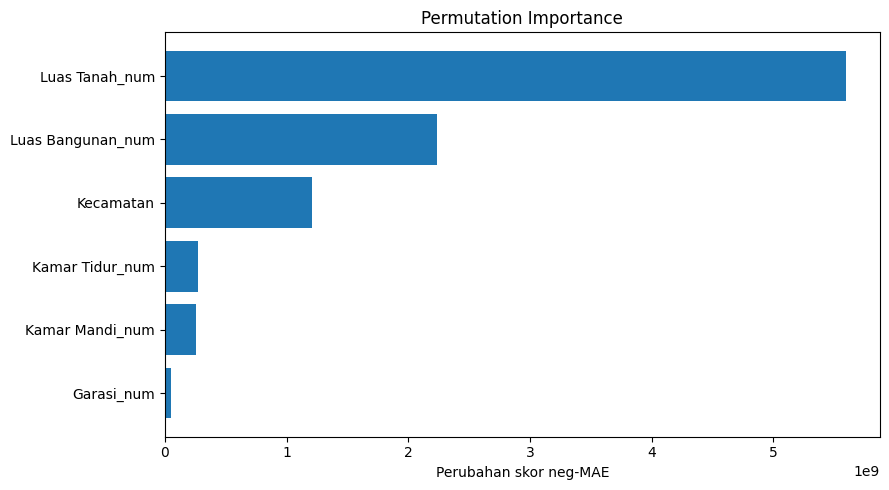

In [ ]:
from sklearn.inspection import permutation_importance

model_terpilih_awal = model_clean_fitted["Random Forest"]

perm = permutation_importance(
    model_terpilih_awal,
    X_test_clean,
    y_test_clean,
    n_repeats=5,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

importance = pd.DataFrame({
    "Fitur": X_test_clean.columns,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Importance", ascending=False)

display(importance)

plt.figure(figsize=(9, 5))
plt.barh(
    importance["Fitur"][::-1],
    importance["Importance"][::-1]
)
plt.xlabel("Perubahan skor neg-MAE")
plt.title("Permutation Importance")
plt.tight_layout()
plt.show()

In [ ]:
fitur_terpilih = [
    "Kamar Tidur_num",
    "Kamar Mandi_num",
    "Luas Tanah_num",
    "Luas Bangunan_num",
    "Kecamatan"
]

In [ ]:
num_selected = [
    c for c in fitur_terpilih
    if c != "Kecamatan"
]

cat_selected = [
    c for c in fitur_terpilih
    if c == "Kecamatan"
]

prep_selected = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            num_selected
        ),
        (
            "cat",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="constant",
                        fill_value="Unknown"
                    )
                ),
                (
                    "onehot",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            cat_selected
        )
    ]
)

model_selection = Pipeline([
    ("preprocessing", prep_selected),
    (
        "model",
        RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    )
])

model_selection.fit(X_train_clean[fitur_terpilih], y_train_clean)

pred_selection = model_selection.predict(
    X_test_clean[fitur_terpilih]
)

display(pd.DataFrame([
    evaluasi(y_test_clean, pred_selection)
]))

,MAE (Rp),MAPE (%),R2
0,2.125692e+09,3163.578699,0.250318


6

In [ ]:
pipeline_rf = Pipeline([
    ("preprocessing", prep_clean),
    (
        "model",
        RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        )
    )
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Mendefinisikan distribusi parameter untuk Random Forest
param_distributions = {
    "model__n_estimators": [50, 100, 200],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

search = RandomizedSearchCV(
    estimator=pipeline_rf,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

search.fit(X_train_clean, y_train_clean)

print("Parameter terbaik:")
print(search.best_params_)

print(
    "MAE validasi silang terbaik (Rp):",
    -search.best_score_
)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Parameter terbaik:
{'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': 30}
MAE validasi silang terbaik (Rp): 2581906293.218238


In [ ]:
model_final = search.best_estimator_

pred_final = model_final.predict(X_test_clean)

hasil_final = evaluasi(y_test_clean, pred_final)

display(
    pd.DataFrame([hasil_final])
)

,MAE (Rp),MAPE (%),R2
0,2.189895e+09,3198.979033,0.227171


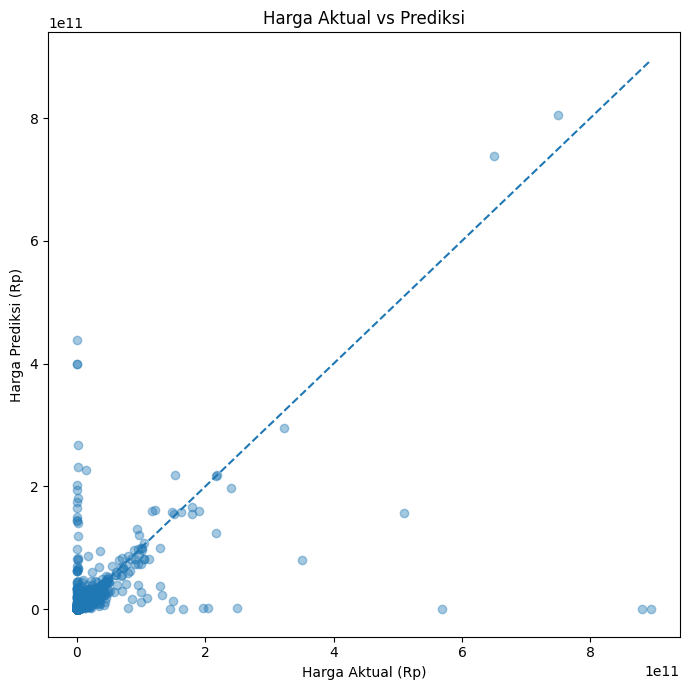

In [ ]:
plt.figure(figsize=(7, 7))
plt.scatter(
    y_test_clean,
    pred_final,
    alpha=0.4
)

batas_min = min(y_test_clean.min(), pred_final.min())
batas_max = max(y_test_clean.max(), pred_final.max())

plt.plot(
    [batas_min, batas_max],
    [batas_min, batas_max],
    linestyle="--"
)

plt.xlabel("Harga Aktual (Rp)")
plt.ylabel("Harga Prediksi (Rp)")
plt.title("Harga Aktual vs Prediksi")
plt.tight_layout()
plt.show()

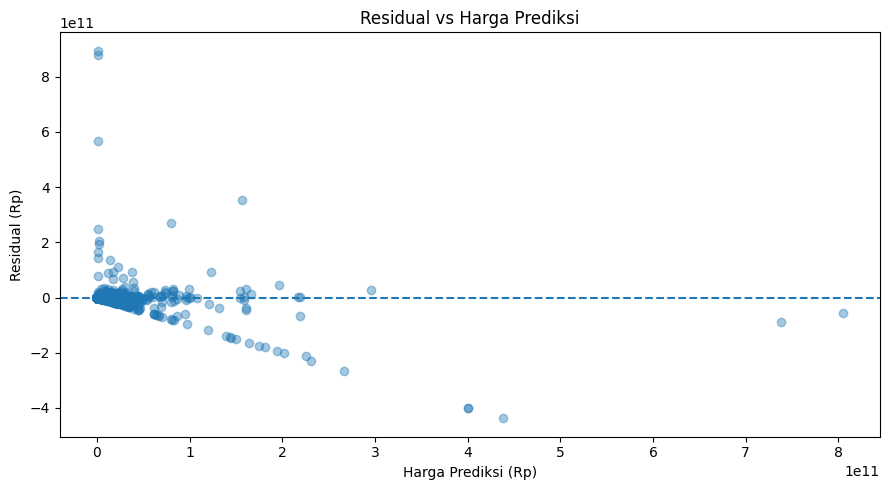

In [ ]:
residual = y_test_clean - pred_final

plt.figure(figsize=(9, 5))
plt.scatter(
    pred_final,
    residual,
    alpha=0.4
)
plt.axhline(0, linestyle="--")
plt.xlabel("Harga Prediksi (Rp)")
plt.ylabel("Residual (Rp)")
plt.title("Residual vs Harga Prediksi")
plt.tight_layout()
plt.show()

7

In [ ]:
import joblib

joblib.dump(
    model_final,
    "model_harga_rumah.joblib"
)

print("Model berhasil disimpan.")

Model berhasil disimpan.


In [ ]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 17.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 23.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:

import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Prediksi Harga Rumah",
    page_icon="🏠",
    layout="centered"
)

@st.cache_resource
def load_model():
    return joblib.load("model_harga_rumah.joblib")

model = load_model()

st.title("Prediksi Harga Rumah")
st.write(
    "Masukkan karakteristik rumah untuk memperoleh "
    "estimasi harga penawaran berdasarkan model."
)

with st.form("form_prediksi"):
    kamar_tidur = st.number_input(
        "Kamar tidur",
        min_value=0,
        max_value=30,
        value=3
    )

    kamar_mandi = st.number_input(
        "Kamar mandi",
        min_value=0,
        max_value=30,
        value=2
    )

    garasi = st.number_input(
        "Jumlah garasi",
        min_value=0,
        max_value=30,
        value=1
    )

    luas_tanah = st.number_input(
        "Luas tanah (m²)",
        min_value=1.0,
        value=100.0
    )

    luas_bangunan = st.number_input(
        "Luas bangunan (m²)",
        min_value=1.0,
        value=80.0
    )

    kecamatan = st.selectbox(
        "Kecamatan",
        [
            "Cinere",
            "Sawangan",
            "Cimanggis",
            "Pancoran Mas",
            "Cilodong",
            "Beji",
            "Sukmajaya",
            "Limo",
            "Tapos",
            "Cipayung",
            "Lainnya"
        ]
    )

    submitted = st.form_submit_button("Prediksi Harga")

if submitted:
    input_data = pd.DataFrame([{
        "Kamar Tidur_num": kamar_tidur,
        "Kamar Mandi_num": kamar_mandi,
        "Garasi_num": garasi,
        "Luas Tanah_num": luas_tanah,
        "Luas Bangunan_num": luas_bangunan,
        "Kecamatan": kecamatan
    }])

    try:
        prediksi = float(model.predict(input_data)[0])

        if prediksi <= 0:
            st.warning(
                "Model menghasilkan estimasi yang tidak positif. "
                "Periksa input dan evaluasi model."
            )
        else:
            st.success(
                f"Estimasi harga: Rp{prediksi:,.0f}"
            )

            st.caption(
                "Hasil ini merupakan estimasi model, "
                "bukan jaminan harga transaksi."
            )

    except Exception as e:
        st.error(f"Prediksi gagal: {e}")


2026-10-27 04:45:14.151 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 04:45:14.154 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 04:45:16.043 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 04:45:16.199 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-10-27 04:45:16.200 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 04:45:16.201 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 04:45:16.202 Thread 'MainThread'

In [ ]:
streamlit
pandas
numpy
scikit-learn
joblib

NameError: name 'streamlit' is not defined

In [ ]:
  streamlit run app.py

SyntaxError: invalid syntax (3255703164.py, line 1)